In [1]:
from src.parametric_estimation import ParametricEstimation
from src.missing_data_generator import MissingDataGenerator
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import logistic
from sklearn.metrics import root_mean_squared_error
from joblib import Parallel, delayed

Error importing in API mode: ImportError("dlopen(/Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib\n  Referenced from: <1984CB9B-890E-3855-A246-270AC6AC4C62> /Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file)")
Trying to import in ABI mode.


In [2]:
n = 2000
d = 20
n_pat = 3
k_range = (0,20)
eps = 1e-2
fast = True # only Xtrain
var_index = 0
p = 0.1

In [3]:
# Specify data model
mdg = MissingDataGenerator(n=n, d=d, n_pat=n_pat, seed=1, distr='logistic') # the patterns is sampled once in the init

In [4]:
# Single job
def job(
        # n:int = None, # sample size
        # d:int = None, # data dimension
        # patterns = None, # arg of mice:ampute
        # prop:float = None, # arg of mice::ampute
        eps: float = None, # clamping scale
        fast: bool = None, # if fast, use fast algorithm of nmm
        var_index:int = None, # which variable
        p:float = None, # quantile
        ):
    X = mdg.get_X()
    _, M = mdg.ampute(X)
    pe = ParametricEstimation(X=X, M=M)
    ps_gmm = pe._propensity_score_Xc(method='gmm', eps=eps)
    ps_nmm = pe._propensity_score_Xc(method='nmm', eps=eps, fast=fast)
    qs = (
        pe.quantile_by_ipw(var_index=var_index, p=p, propensity_score=ps_gmm).item(), 
        pe.quantile_by_ipw(var_index=var_index, p=p, propensity_score=ps_nmm).item(),
        pe.quantile_by_generation(var_index=var_index, p=p).item(),
    )
    ms = np.stack(
        [
            pe.mean_by_ipw(propensity_score=ps_gmm), 
            pe.mean_by_ipw(propensity_score=ps_nmm),
            pe.mean_by_generation(),
        ],
        axis=0
    )
    return qs, ms

In [5]:
B = 1 # CHANGE

results = Parallel(n_jobs=15)(
    delayed(job)(
        eps=eps,
        fast=fast,
        var_index=var_index,
        p=p,
    )
    for _ in range(B)
)

Fast method only supports Xtrain


In [6]:
quantile_results = np.stack([q for q, _ in results])

mean_results = np.stack([
    np.sqrt(np.mean(np.square(m), axis=-1))
    for _, m in results
])

results = (quantile_results, mean_results)

# np.save('results/quantile_results.npy', quantile_results)
# np.save('results/mean_results.npy', mean_results)

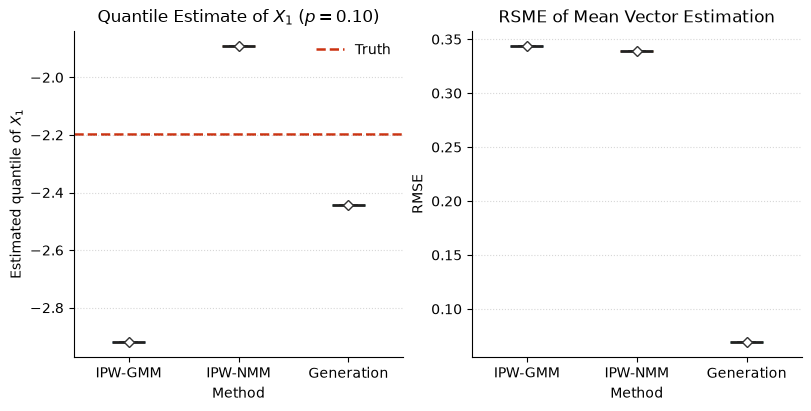

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)

for ax, result in zip(axes, results):

    bp = ax.boxplot(
        result,
        tick_labels=['IPW-GMM', 'IPW-NMM', 'Generation'],
        patch_artist=True,
        widths=0.3,
        showmeans=True,
        meanprops=dict(
            marker="D",
            markerfacecolor="white",
            markeredgecolor="#333333",
            markersize=5,
        ),
        medianprops=dict(color="#222222", linewidth=2),
        whiskerprops=dict(color="#555555", linewidth=1.2),
        capprops=dict(color="#555555", linewidth=1.2),
        flierprops=dict(
            marker="o",
            markersize=4,
            markerfacecolor="#999999",
            markeredgecolor="none",
            alpha=0.6,
        ),
    )

    # Colorblind-friendly palette
    colors = ["#0072B2", "#D55E00", "#009E73"]
    for box, color in zip(bp["boxes"], colors):
        box.set_facecolor(color)
        box.set_alpha(0.75)
        box.set_edgecolor(color)

    ax.yaxis.grid(True, linestyle=":", alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Reference quantile
y_ref = logistic.ppf(p)
axes[0].axhline(
    y=y_ref,
    color="#CC3311",
    linestyle="--",
    linewidth=1.8,
    label="Truth",
    zorder=0,
)

axes[0].set(
    title=fr"Quantile Estimate of $X_1$ ($p={p:.2f}$)",
    xlabel="Method",
    ylabel=r"Estimated quantile of $X_1$",
)

axes[1].set(
    title=fr"RSME of Mean Vector Estimation",
    xlabel="Method",
    ylabel=r"RMSE",
)

axes[0].legend(frameon=False, loc="best")

plt.savefig(f'results/pe_quantile_mean_{n_pat}_patterns_{B}_B.png',dpi=300,
    bbox_inches="tight",)

plt.show()
